
# Basic Machine Learning Implementation - Heart Disease - 10/25/2026 - Lasgat0980


In [40]:

# Import necessary libraries
import pandas as pd
import numpy as np
from datetime import datetime
from IPython.display import display, Markdown

todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "Lasgat0980"

# Load the Heart Disease dataset
data = pd.read_csv('heart_disease_uci.csv')

# Display the first few rows to understand what the data looks like
display(Markdown("### Step 1.2: Load the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
display(data.head())





### Step 1.2: Load the Dataset

Date: 2026-11-08

Student ID: Lasgat0980

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [2]:

display(Markdown("### Step 1.3: Initial Exploration of the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Get a concise summary of the DataFrame
print(data.info())

# Get descriptive statistics that summarize the numerical features
display(data.describe())


### Step 1.3: Initial Exploration of the Dataset

Date: 2026-11-07

Student ID: Lasgat0980

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB
None


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [3]:

display(Markdown("### Step 1.4: Data Cleaning and Preparation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create a copy of the original dataset
cleaned_data = data.copy()

# Replace invalid zero values with missing values
cleaned_data['trestbps'] = cleaned_data['trestbps'].replace(0, np.nan)
cleaned_data['chol'] = cleaned_data['chol'].replace(0, np.nan)

# Check for missing values
print("Missing values in each column:")
print(cleaned_data.isnull().sum())

# Create a binary target for heart disease classification
cleaned_data['heart_disease_present'] = (cleaned_data['num'] > 0).astype(int)

# Display the first five rows
display(cleaned_data.head())


### Step 1.4: Data Cleaning and Preparation

Date: 2026-11-07

Student ID: Lasgat0980

Missing values in each column:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     60
chol        202
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,heart_disease_present
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


In [4]:

# Import libraries for classification
from sklearn.model_selection import train_test_split

display(Markdown("### Step 2.1: Classification - Split the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Select features and target variable
X = cleaned_data.drop(columns=['id', 'num', 'heart_disease_present'])
y = cleaned_data['heart_disease_present']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display training and testing dataset sizes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


### Step 2.1: Classification - Split the Dataset

Date: 2026-11-07

Student ID: Lasgat0980

Training features shape: (736, 14)
Testing features shape: (184, 14)
Training target shape: (736,)
Testing target shape: (184,)


In [32]:

# Import libraries for encoding and scaling
from sklearn.preprocessing import OneHotEncoder, StandardScaler

display(Markdown("### Step 2.2: Classification - Feature Preprocessing"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create copies of the training and testing datasets
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

# Select numerical and categorical features
numerical_features = X_train_processed.select_dtypes(include=['number']).columns
categorical_features = X_train_processed.select_dtypes(exclude=['number']).columns

# Fill missing numerical values using the training data median
for column in numerical_features:
    median_value = X_train_processed[column].median()
    X_train_processed[column] = X_train_processed[column].fillna(median_value)
    X_test_processed[column] = X_test_processed[column].fillna(median_value)

# Fill missing categorical values using the training data mode
for column in categorical_features:
    mode_value = X_train_processed[column].mode()[0]
    X_train_processed[column] = X_train_processed[column].fillna(mode_value)
    X_test_processed[column] = X_test_processed[column].fillna(mode_value)

# Initialize the OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, drop='first')

# Apply one-hot encoding
encoded_train = encoder.fit_transform(X_train_processed[categorical_features])
encoded_test = encoder.transform(X_test_processed[categorical_features])

# Convert the encoded features into DataFrames
encoded_train_df = pd.DataFrame(
    encoded_train,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train_processed.index
)

encoded_test_df = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test_processed.index
)

# Drop original categorical columns and concatenate encoded features
X_train_processed = pd.concat(
    [X_train_processed.drop(columns=categorical_features), encoded_train_df],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_processed.drop(columns=categorical_features), encoded_test_df],
    axis=1
)

# Initialize the StandardScaler
classification_scaler = StandardScaler()

# Apply scaling
X_train_processed[numerical_features] = classification_scaler.fit_transform(
    X_train_processed[numerical_features]
)

X_test_processed[numerical_features] = classification_scaler.transform(
    X_test_processed[numerical_features]
)

# Display the processed dataset sizes
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)



### Step 2.2: Classification - Feature Preprocessing

Date: 2026-11-07

Student ID: Lasgat0980

Processed training shape: (736, 21)
Processed testing shape: (184, 21)


In [6]:

# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

display(Markdown("### Step 2.3: Classification - Model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Initialize the Logistic Regression model
classifier = LogisticRegression(max_iter=200, random_state=42)

# Train the model using the training dataset
classifier.fit(X_train_processed, y_train)

# Predict heart disease using the training dataset
y_train_pred = classifier.predict(X_train_processed)

# Display training accuracy
from sklearn.metrics import accuracy_score
training_accuracy = accuracy_score(y_train, y_train_pred)

print(f"Training Accuracy: {training_accuracy:.4f}")


### Step 2.3: Classification - Model Training

Date: 2026-11-07

Student ID: Lasgat0980

Training Accuracy: 0.8397


In [7]:

# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

display(Markdown("### Step 2.4: Classification - Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Predict heart disease using the testing dataset
y_test_pred = classifier.predict(X_test_processed)

# Calculate model performance metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

# Display evaluation results
print(f"Testing Accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Display classification report and confusion matrix
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


### Step 2.4: Classification - Model Evaluation

Date: 2026-11-07

Student ID: Lasgat0980

Testing Accuracy: 0.8478
Precision: 0.8364
Recall: 0.9020
F1-Score: 0.8679

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82        82
           1       0.84      0.90      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184


Confusion Matrix:
[[64 18]
 [10 92]]


### Step 2.5: Classification Model Findings

I chose Logistic Regression because I wanted to predict whether a patient had heart disease based on their health measurements. Since my classification question focuses on whether heart disease is present or absent, Logistic Regression was a good fit because it predicts the probability of two possible outcomes. It also allows me to examine how different patient characteristics relate to the prediction.

The model achieved 83.97% training accuracy and 84.78% testing accuracy. Its precision was 83.64%, recall was 90.20%, and F1-score was 86.79%.

The confusion matrix showed that the model correctly identified 92 patients with heart disease but missed 10 patients who had the condition. Although the results were encouraging, the model was not perfect, and additional testing would be needed before using it for medical decisions.

I used `max_iter=200` to give the model enough opportunities to converge during training and `random_state=42` to make the results reproducible.

In [8]:

# Import library for regression data splitting
from sklearn.model_selection import train_test_split

display(Markdown("### Step 3.1: Regression - Prepare the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Select features and target variable for regression
regression_data = cleaned_data.dropna(subset=['thalch'])

X_reg = regression_data.drop(columns=['id', 'thalch', 'num', 'heart_disease_present'])
y_reg = regression_data['thalch']

# Split the data into training and testing sets
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Display the training and testing dataset sizes
print(f"Training set size: {X_reg_train.shape[0]} samples")
print(f"Testing set size: {X_reg_test.shape[0]} samples")
print(f"Number of features: {X_reg_train.shape[1]}")


### Step 3.1: Regression - Prepare the Dataset

Date: 2026-11-07

Student ID: Lasgat0980

Training set size: 692 samples
Testing set size: 173 samples
Number of features: 13


In [9]:

# Import libraries for encoding and scaling
from sklearn.preprocessing import OneHotEncoder, StandardScaler

display(Markdown("### Step 3.2: Regression - Feature Preprocessing"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create copies of the training and testing datasets
X_reg_train_processed = X_reg_train.copy()
X_reg_test_processed = X_reg_test.copy()

# Select numerical and categorical features
numerical_features_reg = X_reg_train_processed.select_dtypes(include=['number']).columns
categorical_features_reg = X_reg_train_processed.select_dtypes(exclude=['number']).columns

# Fill missing numerical values using the training data median
for column in numerical_features_reg:
    median_value = X_reg_train_processed[column].median()
    X_reg_train_processed[column] = X_reg_train_processed[column].fillna(median_value)
    X_reg_test_processed[column] = X_reg_test_processed[column].fillna(median_value)

# Fill missing categorical values using the training data mode
for column in categorical_features_reg:
    mode_value = X_reg_train_processed[column].mode()[0]
    X_reg_train_processed[column] = X_reg_train_processed[column].fillna(mode_value)
    X_reg_test_processed[column] = X_reg_test_processed[column].fillna(mode_value)

# Initialize the OneHotEncoder
reg_encoder = OneHotEncoder(sparse_output=False, drop='first')

# Apply one-hot encoding
encoded_reg_train = reg_encoder.fit_transform(X_reg_train_processed[categorical_features_reg])
encoded_reg_test = reg_encoder.transform(X_reg_test_processed[categorical_features_reg])

# Convert the encoded features into DataFrames
encoded_reg_train_df = pd.DataFrame(
    encoded_reg_train,
    columns=reg_encoder.get_feature_names_out(categorical_features_reg),
    index=X_reg_train_processed.index
)

encoded_reg_test_df = pd.DataFrame(
    encoded_reg_test,
    columns=reg_encoder.get_feature_names_out(categorical_features_reg),
    index=X_reg_test_processed.index
)

# Drop original categorical columns and concatenate encoded features
X_reg_train_processed = pd.concat(
    [X_reg_train_processed.drop(columns=categorical_features_reg), encoded_reg_train_df],
    axis=1
)

X_reg_test_processed = pd.concat(
    [X_reg_test_processed.drop(columns=categorical_features_reg), encoded_reg_test_df],
    axis=1
)

# Initialize the StandardScaler
reg_scaler = StandardScaler()

# Apply scaling
X_reg_train_processed[numerical_features_reg] = reg_scaler.fit_transform(
    X_reg_train_processed[numerical_features_reg]
)

X_reg_test_processed[numerical_features_reg] = reg_scaler.transform(
    X_reg_test_processed[numerical_features_reg]
)

# Display the processed dataset sizes
print("Processed training shape:", X_reg_train_processed.shape)
print("Processed testing shape:", X_reg_test_processed.shape)


### Step 3.2: Regression - Feature Preprocessing

Date: 2026-11-07

Student ID: Lasgat0980

Processed training shape: (692, 20)
Processed testing shape: (173, 20)


In [10]:

display(Markdown("### Step 3.3: Regression - Model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Import the regressor model
from sklearn.ensemble import GradientBoostingRegressor

# Instantiate and train the gradient boosting regression model
reg_model = GradientBoostingRegressor(random_state=42)
reg_model.fit(X_reg_train_processed, y_reg_train)

print("Model training completed.")


### Step 3.3: Regression - Model Training

Date: 2026-11-07

Student ID: Lasgat0980

Model training completed.


### Step 3.4: Regression - Model Evaluation

Date: 2026-11-07

Student ID: Lasgat0980

Mean Squared Error: 522.1904290328097
R² Score: 0.2406915706635282


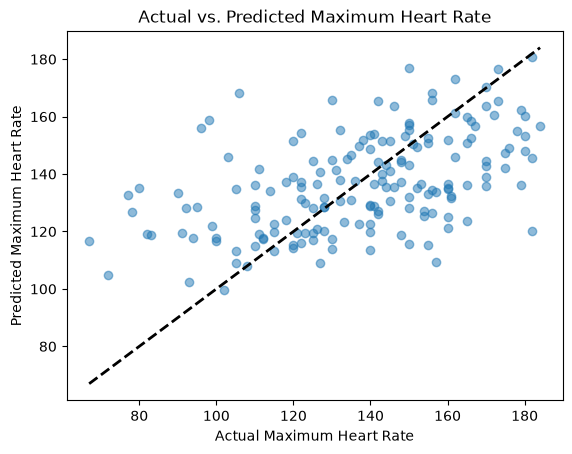

In [11]:

display(Markdown("### Step 3.4: Regression - Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Making predictions with the testing set
y_reg_pred = reg_model.predict(X_reg_test_processed)

# Calculate and print evaluation metrics
mse = mean_squared_error(y_reg_test, y_reg_pred)
r2 = r2_score(y_reg_test, y_reg_pred)
print(f"Mean Squared Error: {mse}")
print(f"R² Score: {r2}")

# Visualization of actual vs. predicted values
plt.scatter(y_reg_test, y_reg_pred, alpha=0.5)
plt.plot([y_reg_test.min(), y_reg_test.max()],
         [y_reg_test.min(), y_reg_test.max()], 'k--', lw=2)
plt.xlabel('Actual Maximum Heart Rate')
plt.ylabel('Predicted Maximum Heart Rate')
plt.title('Actual vs. Predicted Maximum Heart Rate')
plt.show()


### Step 3.5: Regression Model Findings

I chose Gradient Boosting Regression because I wanted to predict a numerical value, which in this case was a patient's maximum heart rate. This algorithm was a good choice because it combines multiple decision trees to learn patterns between patient health measurements and maximum heart rate. I used `random_state=42` to make the results reproducible.

The model achieved a Mean Squared Error (MSE) of 522.19 and an R² score of 0.2407. This means the model explained approximately 24.07% of the variation in maximum heart rate.

The scatter plot showed that several predicted values were noticeably different from the actual values. These results suggest that the model identified some relationships in the data, but its predictions were not very accurate. Additional improvements or different features might help improve its performance.

In [12]:

display(Markdown("### Step 4.1: Clustering - Prepare the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Select patients with heart disease
cluster_data = cleaned_data[cleaned_data['heart_disease_present'] == 1].copy()

# Select numerical features for clustering
cluster_features = cluster_data[['age', 'trestbps', 'chol', 'thalch', 'oldpeak']].copy()

# Fill missing values using the median
cluster_features = cluster_features.fillna(cluster_features.median())

# Display the first five rows
display(cluster_features.head())

# Display the dataset size
print("Clustering dataset shape:", cluster_features.shape)


### Step 4.1: Clustering - Prepare the Dataset

Date: 2026-11-07

Student ID: Lasgat0980

,age,trestbps,chol,thalch,oldpeak
1,67,160.0,286.0,108.0,1.5
2,67,120.0,229.0,129.0,2.6
6,62,140.0,268.0,160.0,3.6
8,63,130.0,254.0,147.0,1.4
9,53,140.0,203.0,155.0,3.1


Clustering dataset shape: (509, 5)


In [13]:

from sklearn.preprocessing import StandardScaler

display(Markdown("### Step 4.2: Clustering - Standardize the Data"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Standardize the data
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_features)

# Display the standardized data
print("Standardized dataset shape:", cluster_scaled.shape)
print(cluster_scaled[:5])


### Step 4.2: Clustering - Standardize the Data

Date: 2026-11-07

Student ID: Lasgat0980

Standardized dataset shape: (509, 5)
[[ 1.27391167  1.38334432  0.67849189 -0.87410942  0.22162581]
 [ 1.27391167 -0.73910408 -0.46181311  0.03266034  1.17946671]
 [ 0.69988455  0.32212012  0.31839558  1.37122522  2.05023117]
 [ 0.81468997 -0.20849198  0.03832066  0.80989156  0.13454936]
 [-0.33336428  0.32212012 -0.98195224  1.15532766  1.61484894]]


### Step 4.3: Clustering - K-Means Model

Date: 2026-11-07

Student ID: Lasgat0980

C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


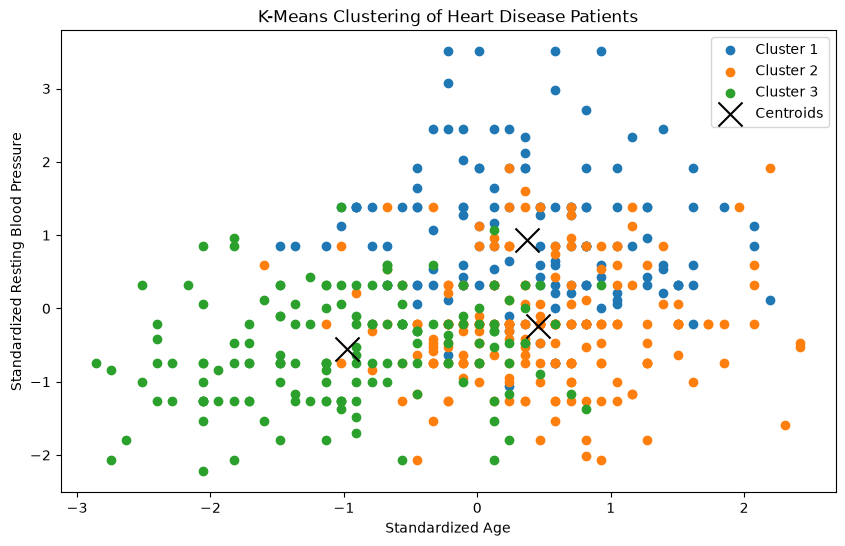

In [14]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

display(Markdown("### Step 4.3: Clustering - K-Means Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Initialize the KMeans model
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)

# Fit the model to the data
kmeans.fit(cluster_scaled)

# Get the cluster labels and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

# Plot the clusters
plt.figure(figsize=(10, 6))
for i in range(k):
    cluster_points = cluster_scaled[labels == i]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1],
                label=f'Cluster {i + 1}')

# Plot the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c='black',
            marker='x', label='Centroids')
plt.xlabel('Standardized Age')
plt.ylabel('Standardized Resting Blood Pressure')
plt.title('K-Means Clustering of Heart Disease Patients')
plt.legend()
plt.show()


### Step 4.4: Clustering - Elbow Method

Date: 2026-11-07

Student ID: Lasgat0980

C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

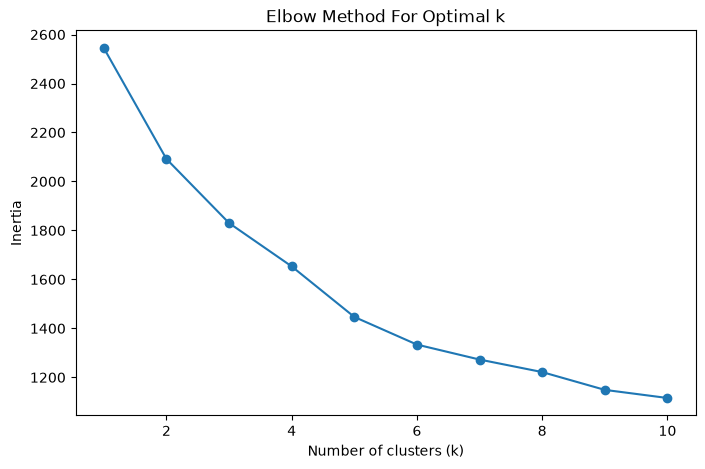

In [15]:

display(Markdown("### Step 4.4: Clustering - Elbow Method"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Use Elbow Method to find optimal k
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(cluster_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()


### Step 4.5: Clustering - Silhouette Score

Date: 2026-11-07

Student ID: Lasgat0980

C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

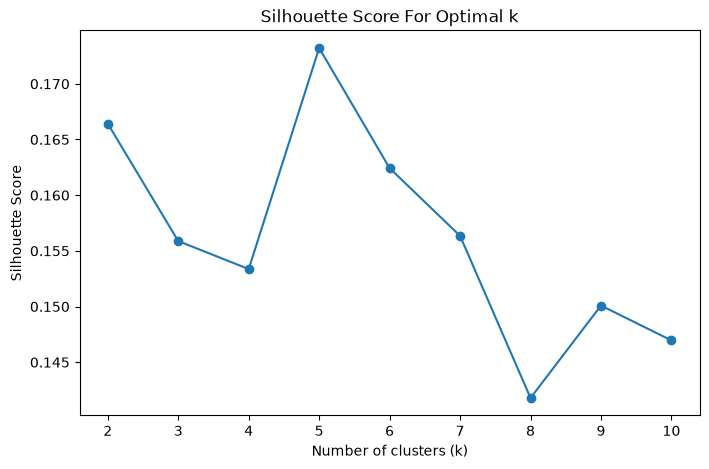

In [16]:

from sklearn.metrics import silhouette_score

display(Markdown("### Step 4.5: Clustering - Silhouette Score"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Silhouette Score
silhouette_scores = []

# Calculate the Silhouette Score to find optimal k
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(cluster_scaled)

    # Silhouette score is only defined for k > 1
    if k > 1:
        score = silhouette_score(cluster_scaled, kmeans.labels_)
        silhouette_scores.append(score)

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(k_values[1:], silhouette_scores, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score For Optimal k')
plt.show()


### Step 4.6: Clustering - Final K-Means Model

Date: 2026-11-07

Student ID: Lasgat0980

C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


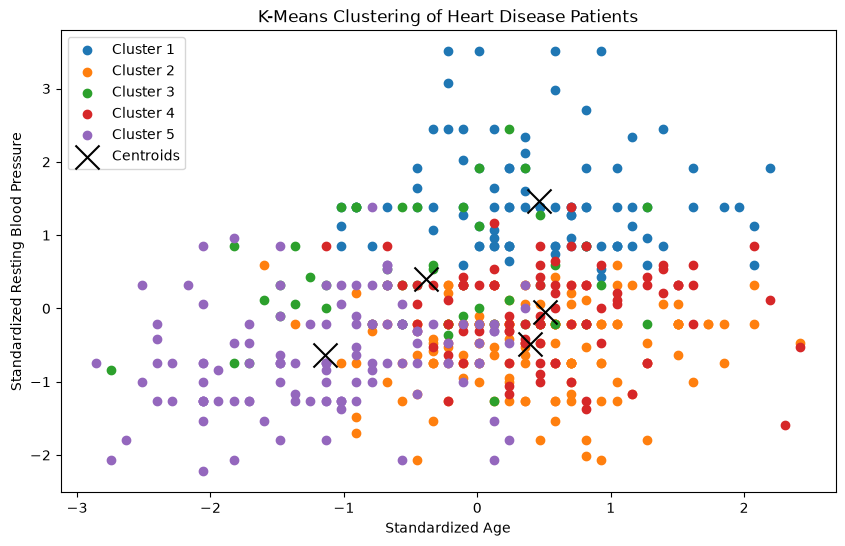

In [17]:

display(Markdown("### Step 4.6: Clustering - Final K-Means Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Initialize the KMeans model
k = 5
kmeans = KMeans(n_clusters=k, random_state=42)

# Fit the model to the data
kmeans.fit(cluster_scaled)

# Get the cluster labels and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

# Plot the clusters
plt.figure(figsize=(10, 6))
for i in range(k):
    cluster_points = cluster_scaled[labels == i]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1],
                label=f'Cluster {i + 1}')

# Plot the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c='black',
            marker='x', label='Centroids')
plt.xlabel('Standardized Age')
plt.ylabel('Standardized Resting Blood Pressure')
plt.title('K-Means Clustering of Heart Disease Patients')
plt.legend()
plt.show()


### Step 4.7: Clustering Model Findings

I chose K-Means Clustering because I wanted to identify groups of patients with heart disease who shared similar health characteristics. This algorithm was a good choice because it groups patients based on similarities in their measurements without needing predefined categories.

I initially used `n_clusters=3` and `random_state=42`. I then used the Elbow Method and Silhouette Score to evaluate different numbers of clusters. The Elbow Method suggested approximately 5–6 clusters, while the highest Silhouette Score was approximately 0.173 at 5 clusters. Based on these results, I selected `n_clusters=5` for my final model.

The final visualization showed five patient groups, but there was some overlap between them. The relatively low Silhouette Score suggests that the clusters were not strongly separated. Although K-Means identified some patterns in the data, additional analysis would be needed to understand the differences between the groups.

## Part 4: Advanced Modeling and Optimization

### Step 5.1: Classification - Hyperparameter Tuning

In [18]:

from sklearn.model_selection import GridSearchCV

display(Markdown("### Step 5.2: Classification - Grid Search"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the hyperparameters to test
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

# Initialize Grid Search
grid_search = GridSearchCV(LogisticRegression(max_iter=200, random_state=42), param_grid, cv=5, scoring='accuracy')

# Perform hyperparameter search
grid_search.fit(X_train_processed, y_train)

# Get the optimal hyperparameters
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)


### Step 5.2: Classification - Grid Search

Date: 2026-11-07

Student ID: Lasgat0980

Best Hyperparameters: {'C': 1}
Best Cross-Validation Accuracy: 0.826034197462769


In [19]:

display(Markdown("### Step 5.3: Classification - Retrain Optimized Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Get the model with the best hyperparameters
optimized_classifier = grid_search.best_estimator_

# Retrain the optimized model
optimized_classifier.fit(X_train_processed, y_train)

print("Optimized classification model training completed.")
print("Best C value:", optimized_classifier.C)


### Step 5.3: Classification - Retrain Optimized Model

Date: 2026-11-07

Student ID: Lasgat0980

Optimized classification model training completed.
Best C value: 1


In [20]:

display(Markdown("### Step 5.4: Classification - Optimized Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Make predictions using the optimized model
y_optimized_pred = optimized_classifier.predict(X_test_processed)

# Evaluate the optimized model
optimized_accuracy = accuracy_score(y_test, y_optimized_pred)
optimized_precision = precision_score(y_test, y_optimized_pred)
optimized_recall = recall_score(y_test, y_optimized_pred)
optimized_f1 = f1_score(y_test, y_optimized_pred)

# Display performance metrics
print(f"Optimized Testing Accuracy: {optimized_accuracy:.4f}")
print(f"Optimized Precision: {optimized_precision:.4f}")
print(f"Optimized Recall: {optimized_recall:.4f}")
print(f"Optimized F1-Score: {optimized_f1:.4f}")

# Display confusion matrix
print("\nOptimized Confusion Matrix:")
print(confusion_matrix(y_test, y_optimized_pred))

# Compare original and optimized accuracy
print("\nOriginal Testing Accuracy: 0.8478")
print(f"Optimized Testing Accuracy: {optimized_accuracy:.4f}")


### Step 5.4: Classification - Optimized Model Evaluation

Date: 2026-11-07

Student ID: Lasgat0980

Optimized Testing Accuracy: 0.8478
Optimized Precision: 0.8364
Optimized Recall: 0.9020
Optimized F1-Score: 0.8679

Optimized Confusion Matrix:
[[64 18]
 [10 92]]

Original Testing Accuracy: 0.8478
Optimized Testing Accuracy: 0.8478



### Step 5.5: Classification Optimization Summary

Grid Search was used to tune the Logistic Regression model with L2 regularization.

Best C Value: 1

Cross-Validation Accuracy: 82.60%

Original Testing Accuracy: 84.78%

Optimized Testing Accuracy: 84.78%

Result: The model's testing accuracy stayed the same after optimization.




In [21]:

display(Markdown("### Step 5.6: Regression - Grid Search"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the hyperparameters to test
param_grid_reg = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3]
}

# Initialize Grid Search
grid_search_reg = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid_reg,
    cv=5,
    scoring='neg_mean_squared_error'
)

# Perform hyperparameter search
grid_search_reg.fit(X_reg_train_processed, y_reg_train)

# Display the optimal hyperparameters
print("Best Hyperparameters:", grid_search_reg.best_params_)
print("Best Cross-Validation MSE:", -grid_search_reg.best_score_)


### Step 5.6: Regression - Grid Search

Date: 2026-11-07

Student ID: Lasgat0980

Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
Best Cross-Validation MSE: 407.9830871892872


In [22]:

display(Markdown("### Step 5.7: Regression - Regularization and Retraining"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Get the best hyperparameters from Grid Search
best_params_reg = grid_search_reg.best_params_

# Retrain the optimized model with early stopping
optimized_reg_model = GradientBoostingRegressor(
    n_estimators=best_params_reg['n_estimators'],
    learning_rate=best_params_reg['learning_rate'],
    max_depth=best_params_reg['max_depth'],
    n_iter_no_change=5,
    validation_fraction=0.1,
    random_state=42
)

optimized_reg_model.fit(X_reg_train_processed, y_reg_train)

print("Optimized regression model training completed.")
print("Best Hyperparameters:", best_params_reg)
print("Number of Trees Used:", optimized_reg_model.n_estimators_)


### Step 5.7: Regression - Regularization and Retraining

Date: 2026-11-07

Student ID: Lasgat0980

Optimized regression model training completed.
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
Number of Trees Used: 39


### Step 5.8: Regression - Optimized Model Evaluation

Date: 2026-11-07

Student ID: Lasgat0980

Original MSE: 522.19
Optimized MSE: 504.12
Original R² Score: 0.2407
Optimized R² Score: 0.2670


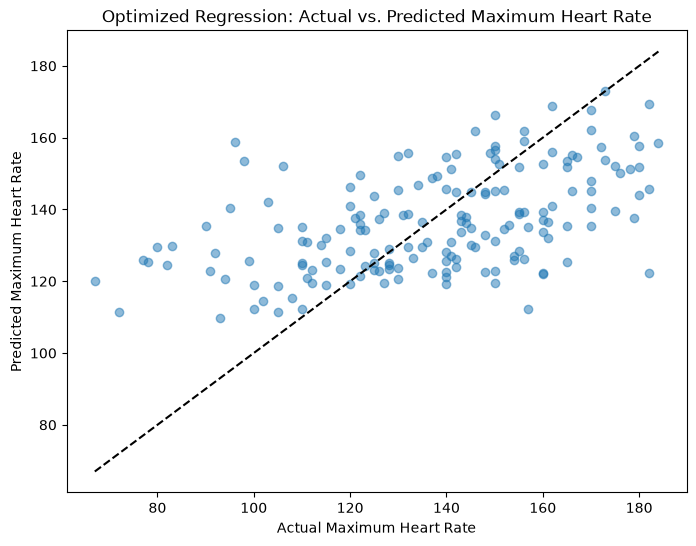

In [23]:

display(Markdown("### Step 5.8: Regression - Optimized Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Make predictions using the optimized model
y_reg_optimized_pred = optimized_reg_model.predict(X_reg_test_processed)

# Evaluate the optimized model
optimized_mse = mean_squared_error(y_reg_test, y_reg_optimized_pred)
optimized_r2 = r2_score(y_reg_test, y_reg_optimized_pred)

# Display the performance metrics
print("Original MSE: 522.19")
print(f"Optimized MSE: {optimized_mse:.2f}")
print("Original R² Score: 0.2407")
print(f"Optimized R² Score: {optimized_r2:.4f}")

# Visualize actual vs. predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_reg_test, y_reg_optimized_pred, alpha=0.5)
plt.plot([y_reg_test.min(), y_reg_test.max()],
         [y_reg_test.min(), y_reg_test.max()], 'k--')
plt.xlabel("Actual Maximum Heart Rate")
plt.ylabel("Predicted Maximum Heart Rate")
plt.title("Optimized Regression: Actual vs. Predicted Maximum Heart Rate")
plt.show()



### Step 5.9: Regression Optimization Summary

Optimization Method: Grid Search with 5-fold cross-validation

Best Hyperparameters: learning_rate=0.1, max_depth=3, n_estimators=50

Regularization: Early stopping (39 trees used)

Original MSE: 522.19

Optimized MSE: 504.12

Original R² Score: 0.2407

Optimized R² Score: 0.2670

Result: The regression model's performance improved after optimization.



### Step 5.10: Clustering - Hyperparameter Tuning


In [24]:

from sklearn.model_selection import ParameterGrid

display(Markdown("### Step 5.11: Clustering - Grid Search"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the hyperparameters to test
param_grid_cluster = {
    'n_clusters': [3, 4, 5, 6, 7],
    'n_init': [10, 20]
}

# Perform Grid Search using Silhouette Score
best_score_cluster = -1
best_params_cluster = None

for params in ParameterGrid(param_grid_cluster):
    cluster_model = KMeans(
        n_clusters=params['n_clusters'],
        n_init=params['n_init'],
        random_state=42
    )
    cluster_labels = cluster_model.fit_predict(cluster_scaled)
    score = silhouette_score(cluster_scaled, cluster_labels)

    if score > best_score_cluster:
        best_score_cluster = score
        best_params_cluster = params

# Display the optimal hyperparameters
print("Best Hyperparameters:", best_params_cluster)
print("Best Silhouette Score:", best_score_cluster)


### Step 5.11: Clustering - Grid Search

Date: 2026-11-07

Student ID: Lasgat0980

C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Best Hyperparameters: {'n_clusters': 4, 'n_init': 10}
Best Silhouette Score: 0.17879834151326493


In [25]:

display(Markdown("### Step 5.12: Clustering - Retrain Optimized Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Retrain K-Means using the best hyperparameters
optimized_kmeans = KMeans(
    n_clusters=best_params_cluster['n_clusters'],
    n_init=best_params_cluster['n_init'],
    random_state=42
)

optimized_kmeans.fit(cluster_scaled)

# Get the optimized cluster labels and centroids
optimized_labels = optimized_kmeans.labels_
optimized_centroids = optimized_kmeans.cluster_centers_

print("Optimized clustering model training completed.")
print("Number of Clusters:", optimized_kmeans.n_clusters)
print("Number of Initializations:", optimized_kmeans.n_init)


### Step 5.12: Clustering - Retrain Optimized Model

Date: 2026-11-07

Student ID: Lasgat0980

Optimized clustering model training completed.
Number of Clusters: 4
Number of Initializations: 10


C:\Users\ldick\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


### Step 5.13: Clustering - Optimized Model Evaluation

Date: 2026-11-07

Student ID: Lasgat0980

Original Silhouette Score: Approximately 0.173
Optimized Silhouette Score: 0.1788
Optimized Number of Clusters: 4


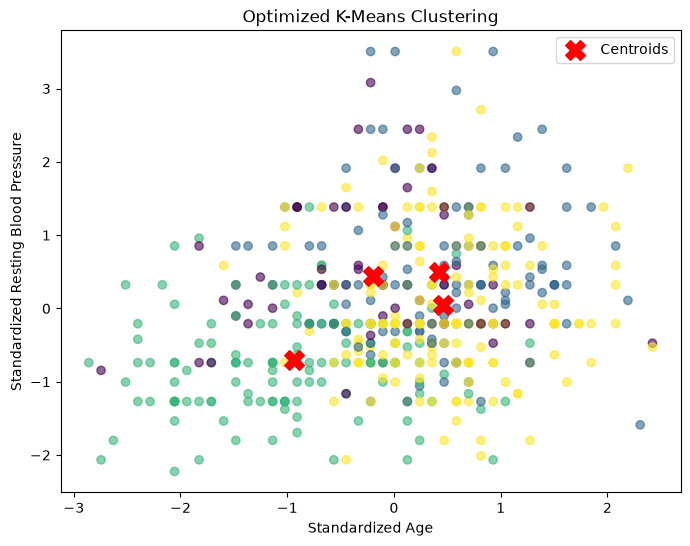

In [26]:

display(Markdown("### Step 5.13: Clustering - Optimized Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Calculate the optimized Silhouette Score
optimized_silhouette = silhouette_score(cluster_scaled, optimized_labels)

# Display the evaluation results
print("Original Silhouette Score: Approximately 0.173")
print(f"Optimized Silhouette Score: {optimized_silhouette:.4f}")
print("Optimized Number of Clusters:", optimized_kmeans.n_clusters)

# Visualize the optimized clusters
plt.figure(figsize=(8, 6))
plt.scatter(cluster_scaled[:, 0], cluster_scaled[:, 1],
            c=optimized_labels, cmap='viridis', alpha=0.6)
plt.scatter(optimized_centroids[:, 0], optimized_centroids[:, 1],
            c='red', marker='X', s=200, label='Centroids')
plt.xlabel("Standardized Age")
plt.ylabel("Standardized Resting Blood Pressure")
plt.title("Optimized K-Means Clustering")
plt.legend()
plt.show()



### Step 5.14: Clustering Optimization Summary

Optimization Method: Grid Search

Best Hyperparameters: n_clusters=4, n_init=10

Original Number of Clusters: 5

Optimized Number of Clusters: 4

Original Silhouette Score: Approximately 0.173

Optimized Silhouette Score: 0.1788

Result: The clustering model showed a slight improvement in cluster separation after optimization.



## Part 5: Scenario and Impact Analysis

### Step 6.1: Scenario Development



### Step 6.2: Scenario Assumptions and Rationale

**Scenario 1: Lower Health Measurements**

Assumption: Cholesterol and resting blood pressure decrease by 10% from their original values.

Rationale: This scenario tests how the model's heart disease predictions change when these two measurements are lower.

**Scenario 2: Baseline Measurements**

Assumption: Cholesterol and resting blood pressure remain at their original values.

Rationale: This provides a starting point for comparing the other two scenarios.

**Scenario 3: Higher Health Measurements**

Assumption: Cholesterol and resting blood pressure increase by 10% from their original values.

Rationale: This scenario tests how the model's heart disease predictions change when these two measurements are higher.

**Purpose:** Compare the model's predictions across all three scenarios to understand how sensitive the model is to changes in cholesterol and resting blood pressure.


In [33]:


display(Markdown("### Step 6.3: Prepare Scenario Data"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create copies of the processed test data
baseline_scenario = X_test_processed.copy()
lower_scenario = X_test_processed.copy()
higher_scenario = X_test_processed.copy()

# Identify the numerical features
chol_index = numerical_features.get_loc('chol')
bp_index = numerical_features.get_loc('trestbps')

# Convert standardized values back to original measurements
original_chol = (
    X_test_processed['chol'] * classification_scaler.scale_[chol_index]
    + classification_scaler.mean_[chol_index]
)

original_bp = (
    X_test_processed['trestbps'] * classification_scaler.scale_[bp_index]
    + classification_scaler.mean_[bp_index]
)

# Scenario 1: Decrease each patient's measurements by 10%
lower_scenario['chol'] = (
    original_chol * 0.90 - classification_scaler.mean_[chol_index]
) / classification_scaler.scale_[chol_index]

lower_scenario['trestbps'] = (
    original_bp * 0.90 - classification_scaler.mean_[bp_index]
) / classification_scaler.scale_[bp_index]

# Scenario 3: Increase each patient's measurements by 10%
higher_scenario['chol'] = (
    original_chol * 1.10 - classification_scaler.mean_[chol_index]
) / classification_scaler.scale_[chol_index]

higher_scenario['trestbps'] = (
    original_bp * 1.10 - classification_scaler.mean_[bp_index]
) / classification_scaler.scale_[bp_index]

# Display the scenario dataset sizes
print("Baseline Scenario Shape:", baseline_scenario.shape)
print("Lower Scenario Shape:", lower_scenario.shape)
print("Higher Scenario Shape:", higher_scenario.shape)


### Step 6.3: Prepare Scenario Data

Date: 2026-11-07

Student ID: Lasgat0980

Baseline Scenario Shape: (184, 21)
Lower Scenario Shape: (184, 21)
Higher Scenario Shape: (184, 21)


In [35]:

display(Markdown("### Step 6.4: Scenario Predictions"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Predict heart disease probabilities for each scenario
baseline_predictions = optimized_classifier.predict_proba(baseline_scenario)[:, 1]
lower_predictions = optimized_classifier.predict_proba(lower_scenario)[:, 1]
higher_predictions = optimized_classifier.predict_proba(higher_scenario)[:, 1]

# Calculate the average predicted probability
baseline_average = baseline_predictions.mean()
lower_average = lower_predictions.mean()
higher_average = higher_predictions.mean()

# Display the results
print(f"Baseline Average Probability: {baseline_average:.4f}")
print(f"Lower Measurements Average Probability: {lower_average:.4f}")
print(f"Higher Measurements Average Probability: {higher_average:.4f}")


### Step 6.4: Scenario Predictions

Date: 2026-11-07

Student ID: Lasgat0980

Baseline Average Probability: 0.5680
Lower Measurements Average Probability: 0.5476
Higher Measurements Average Probability: 0.5881


### Step 6.5: Scenario Comparison Visualization

Date: 2026-11-07

Student ID: Lasgat0980

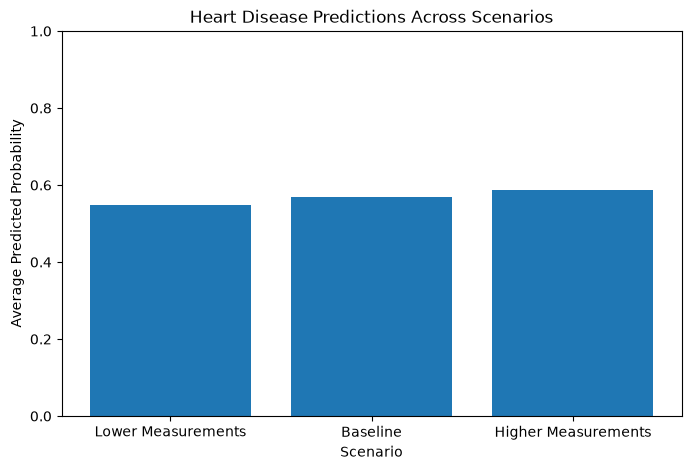

In [36]:

display(Markdown("### Step 6.5: Scenario Comparison Visualization"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Compare average predicted probabilities
scenarios = ['Lower Measurements', 'Baseline', 'Higher Measurements']
average_probabilities = [
    lower_average,
    baseline_average,
    higher_average
]

# Create the visualization
plt.figure(figsize=(8, 5))
plt.bar(scenarios, average_probabilities)
plt.xlabel("Scenario")
plt.ylabel("Average Predicted Probability")
plt.title("Heart Disease Predictions Across Scenarios")
plt.ylim(0, 1)
plt.show()


In [37]:

display(Markdown("### Step 6.6: Sensitivity Analysis - Cholesterol"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create copies of the baseline scenario
chol_lower = baseline_scenario.copy()
chol_higher = baseline_scenario.copy()

# Apply a 10% decrease and increase to cholesterol
chol_lower['chol'] = lower_scenario['chol']
chol_higher['chol'] = higher_scenario['chol']

# Predict heart disease probabilities
chol_lower_predictions = optimized_classifier.predict_proba(chol_lower)[:, 1]
chol_higher_predictions = optimized_classifier.predict_proba(chol_higher)[:, 1]

# Compare average predicted probabilities
print(f"Baseline Probability: {baseline_average:.4f}")
print(f"Cholesterol Decreased 10%: {chol_lower_predictions.mean():.4f}")
print(f"Cholesterol Increased 10%: {chol_higher_predictions.mean():.4f}")


### Step 6.6: Sensitivity Analysis - Cholesterol

Date: 2026-11-07

Student ID: Lasgat0980

Baseline Probability: 0.5680
Cholesterol Decreased 10%: 0.5538
Cholesterol Increased 10%: 0.5820


In [38]:

display(Markdown("### Step 6.7: Sensitivity Analysis - Resting Blood Pressure"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create copies of the baseline scenario
bp_lower = baseline_scenario.copy()
bp_higher = baseline_scenario.copy()

# Apply a 10% decrease and increase to resting blood pressure
bp_lower['trestbps'] = lower_scenario['trestbps']
bp_higher['trestbps'] = higher_scenario['trestbps']

# Predict heart disease probabilities
bp_lower_predictions = optimized_classifier.predict_proba(bp_lower)[:, 1]
bp_higher_predictions = optimized_classifier.predict_proba(bp_higher)[:, 1]

# Compare average predicted probabilities
print(f"Baseline Probability: {baseline_average:.4f}")
print(f"Blood Pressure Decreased 10%: {bp_lower_predictions.mean():.4f}")
print(f"Blood Pressure Increased 10%: {bp_higher_predictions.mean():.4f}")


### Step 6.7: Sensitivity Analysis - Resting Blood Pressure

Date: 2026-11-07

Student ID: Lasgat0980

Baseline Probability: 0.5680
Blood Pressure Decreased 10%: 0.5618
Blood Pressure Increased 10%: 0.5741


### Step 6.8: Sensitivity Analysis Visualization

Date: 2026-11-07

Student ID: Lasgat0980

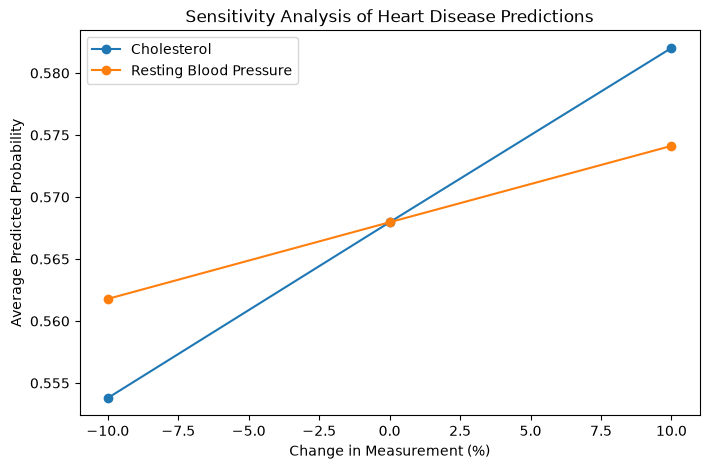

In [39]:

display(Markdown("### Step 6.8: Sensitivity Analysis Visualization"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the percentage changes
percentage_changes = [-10, 0, 10]

# Collect the average predicted probabilities
chol_sensitivity = [
    chol_lower_predictions.mean(),
    baseline_average,
    chol_higher_predictions.mean()
]

bp_sensitivity = [
    bp_lower_predictions.mean(),
    baseline_average,
    bp_higher_predictions.mean()
]

# Plot the sensitivity results
plt.figure(figsize=(8, 5))
plt.plot(percentage_changes, chol_sensitivity, marker='o', label='Cholesterol')
plt.plot(percentage_changes, bp_sensitivity, marker='o', label='Resting Blood Pressure')
plt.xlabel("Change in Measurement (%)")
plt.ylabel("Average Predicted Probability")
plt.title("Sensitivity Analysis of Heart Disease Predictions")
plt.legend()
plt.show()



### Step 6.9: Sensitivity and Impact Analysis Findings

**Features Tested:** Cholesterol and resting blood pressure

**Changes Tested:** -10%, 0%, and +10%

**Baseline Average Predicted Probability:** 56.80%

**Cholesterol Results:** 55.38% to 58.20%

**Resting Blood Pressure Results:** 56.18% to 57.41%

**Findings:** The model's predictions changed more when cholesterol levels were adjusted than when resting blood pressure was adjusted. Increasing either measurement raised the average predicted probability of heart disease, while decreasing either measurement lowered it.

**Potential Impact:** These results suggest that the model is more sensitive to cholesterol changes within the scenarios tested. However, the predictions do not prove that changing these measurements would directly change a patient's actual heart disease risk. The model would need further validation before being used to support medical decisions.
